> 🔓 **SOLUTIONS EDITION**: this is the instructor copy with worked solutions and executed outputs. Please attempt every problem in the student notebook first; struggling is where learning happens.

# 📘 Lesson 10: Logistic Regression
*From a straight line to a probability: the workhorse of classification*

| ⏱️ Time | 🎚️ Level | 🧰 Prerequisites |
|---|---|---|
| ~130 min | 🟡 Intermediate | Lessons 01–02, 09 |

---
## 🎬 The Hook
A teacher wants to predict **pass or fail** from study hours. She fits a straight line through the 0/1 outcomes… and the line predicts **1.4** for a student who studied 12 hours and **−0.3** for one who studied none. A probability of 140 %? Negative 30 %?

The fix is an elegant three-step trick: compute a linear score (as in regression), pass it through an S-shaped **squashing function** that maps any number into (0, 1), and read the output as a **probability**. That is **logistic regression**: despite its name, a *classification* algorithm, and quite possibly the most widely deployed model in the world (credit scoring, medical risk, click prediction, A/B-test analysis…).

---
## 🎯 Learning Objectives
By the end of this notebook you will be able to:

1. Explain why linear regression fails for yes/no targets and how the **sigmoid** fixes it.
2. Move fluently between **probability, odds and log-odds**, and read coefficients as **odds ratios**.
3. Derive the log-loss from maximum likelihood and its gradient $\mathbf X^\top(\mathbf p-\mathbf y)/n$.
4. Implement logistic regression **from scratch** with gradient descent *and* Newton's method, and match scikit-learn.
5. Use L2 / L1 regularisation (`C`), and see why separable data breaks the unregularised model.
6. Draw linear decision boundaries, bend them with polynomial features, and extend to multiple classes (softmax vs one-vs-rest).
7. Apply it end-to-end to a loan-approval dataset and communicate the result.

## 🗺️ Roadmap

- Why linear regression fails for classes
- Sigmoid, odds and log-odds
- Maximum likelihood → log loss → gradient
- A hand-worked example
- From scratch: gradient descent & Newton
- Interpretation: odds ratios
- Regularisation & separable data
- Decision boundaries (and bending them)
- Multi-class: softmax vs one-vs-rest
- Loan approval end-to-end
- Cheat-sheet, worked examples, problems, quiz

> 💡 **How to use this notebook:** run cells top to bottom. Read the text *before* you run the code. When you reach a 🧩 **Problem**, try it yourself first, open the hints one at a time, and only then peek at the solutions notebook.

In [1]:
import sys, os
sys.path.insert(0, os.path.abspath(".."))      # so we can import course_utils.py
from course_utils import *                      # np, pd, plt, check(), data_path(), ...
import numpy as np, pandas as pd, matplotlib.pyplot as plt
%matplotlib inline
RANDOM_STATE = 42
print("Setup complete ✅")
from sklearn.datasets import load_breast_cancer, load_iris, make_moons, make_blobs
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.preprocessing import StandardScaler, PolynomialFeatures, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.multiclass import OneVsRestClassifier
from sklearn.metrics import accuracy_score, roc_auc_score, log_loss, confusion_matrix, classification_report

Setup complete ✅


---
## 🚫 1. Why not just use linear regression?

Let's simulate pass/fail data where the *true* chance of passing climbs smoothly with study hours, then try both models.

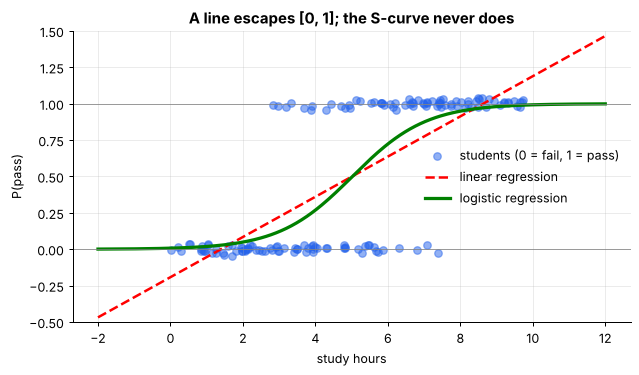

Linear regression predicts for 12 hours: [1.47]  and for 0 hours: [-0.19]


In [2]:
rng = np.random.default_rng(3)
hours = rng.uniform(0, 10, 150)
p_true = 1 / (1 + np.exp(-1.1 * (hours - 5)))
passed = (rng.random(150) < p_true).astype(int)

lin = LinearRegression().fit(hours[:, None], passed)
logit = LogisticRegression().fit(hours[:, None], passed)
g = np.linspace(-2, 12, 300)[:, None]
plt.figure(figsize=(8, 4.2)); plt.scatter(hours, passed + np.random.default_rng(0).normal(0, 0.02, 150), alpha=0.5, label="students (0 = fail, 1 = pass)")
plt.plot(g, lin.predict(g), "r--", lw=2, label="linear regression"); plt.plot(g, logit.predict_proba(g)[:, 1], "g", lw=2.6, label="logistic regression")
plt.axhline(0, color="gray", lw=0.6); plt.axhline(1, color="gray", lw=0.6); plt.ylim(-0.5, 1.5); plt.xlabel("study hours"); plt.ylabel("P(pass)"); plt.legend(); plt.title("A line escapes [0, 1]; the S-curve never does"); plt.show()
print("Linear regression predicts for 12 hours:", lin.predict([[12]]).round(2), " and for 0 hours:", lin.predict([[0]]).round(2))

Linear regression also has a deeper problem: residuals of a 0/1 target can't be normally distributed, and one far-away point can tilt the line. We need a model whose output is **always a valid probability**.

---
## 📐 2. Sigmoid, odds and log-odds

**Step 1: a linear score:** $z=\mathbf w\cdot\mathbf x+b$ (any real number). **Step 2: squash it** with the **sigmoid** (logistic) function:

$$\sigma(z)=\frac{1}{1+e^{-z}}\qquad\Longrightarrow\qquad P(y=1\mid\mathbf x)=\sigma(\mathbf w\cdot\mathbf x+b)$$

Properties worth memorising: $\sigma(0)=0.5$; $\sigma(z)\to1$ as $z\to+\infty$ and $\to0$ as $z\to-\infty$; **$\sigma(-z)=1-\sigma(z)$**; and the derivative is beautifully simple: $\sigma'(z)=\sigma(z)\,(1-\sigma(z))$.

### Three languages for the same thing
| Language | Formula | Range | Example (p = 0.8) |
|---|---|---|---|
| Probability | $p$ | 0 to 1 | 0.8 |
| **Odds** | $\dfrac{p}{1-p}$ | 0 to ∞ | 4 ("4 to 1 in favour") |
| **Log-odds (logit)** | $\ln\dfrac{p}{1-p}$ | −∞ to +∞ | 1.386 |

The sigmoid is exactly the inverse of the logit, so the model says: **the log-odds are a linear function of the features**:

$$\ln\frac{p}{1-p}=b+w_1x_1+\dots+w_px_p$$

**Interpretation:** raising $x_j$ by one unit adds $w_j$ to the log-odds, i.e. **multiplies the odds by $e^{w_j}$** (the *odds ratio*). Linear regression's "holding everything else constant" logic carries over: on the log-odds scale.

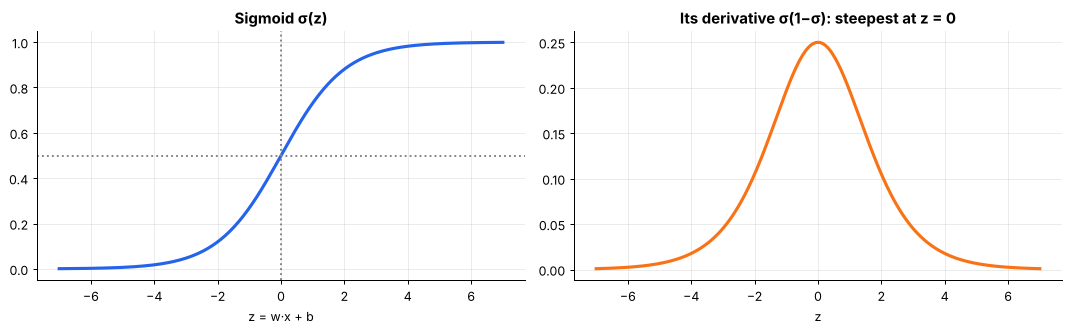

In [3]:
z = np.linspace(-7, 7, 300); sig = 1 / (1 + np.exp(-z))
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
ax[0].plot(z, sig, lw=2.5); ax[0].axhline(0.5, color="gray", ls=":"); ax[0].axvline(0, color="gray", ls=":"); ax[0].set_title("Sigmoid σ(z)"); ax[0].set_xlabel("z = w·x + b")
ax[1].plot(z, sig * (1 - sig), lw=2.5, color="#f97316"); ax[1].set_title("Its derivative σ(1−σ): steepest at z = 0"); ax[1].set_xlabel("z")
plt.tight_layout(); plt.show()

### Where does the loss come from? Maximum likelihood

If the model says $p_i=P(y_i=1\mid\mathbf x_i)$, the probability it assigns to the **observed** label is $p_i^{y_i}(1-p_i)^{1-y_i}$ (just $p_i$ if $y_i=1$, just $1-p_i$ if $y_i=0$). Assuming independent examples, the **likelihood** of the whole dataset is the product over $i$. Maximise its logarithm, or equivalently *minimise the negative mean log-likelihood*: the **log loss** from Lesson 09:

$$J(\mathbf w,b)=-\frac1n\sum_{i=1}^n\Big[y_i\ln p_i+(1-y_i)\ln(1-p_i)\Big]$$

Two facts make this loss lovable: it is **convex** (one global minimum; no local-minimum worries), and its gradient has the same shape as in linear regression:

$$\boxed{\nabla_{\mathbf w}J=\frac1n\mathbf X^\top(\mathbf p-\mathbf y)\qquad\frac{\partial J}{\partial b}=\frac1n\sum_i(p_i-y_i)}$$

"Prediction minus truth, weighted by the features." (The sigmoid's derivative cancels the log's; algebra at its most generous.) Unlike linear regression there is **no closed-form solution**, so we iterate: gradient descent, or **Newton's method** which uses the curvature (Hessian) $\mathbf H=\frac1n\mathbf X^\top\mathrm{diag}\bigl(p_i(1-p_i)\bigr)\mathbf X$ to take much smarter steps: $\theta\leftarrow\theta-\mathbf H^{-1}\nabla J$ (a.k.a. *iteratively reweighted least squares*).

---
## ✍️ 3. A hand-worked example

Suppose a fitted model is $z=-4+0.8\times\text{hours}$. What are the probabilities, odds and the 50 % study time?

In [4]:
b, w = -4.0, 0.8
tbl = pd.DataFrame({"hours": [2, 5, 8, 10]}); tbl["z (log-odds)"] = b + w * tbl["hours"]
tbl["P(pass)"] = 1 / (1 + np.exp(-tbl["z (log-odds)"])); tbl["odds"] = tbl["P(pass)"] / (1 - tbl["P(pass)"])
display(tbl.round(3))
print("odds ratio per extra hour = e^0.8 =", round(np.exp(0.8), 3), "  (each extra hour multiplies the odds of passing by about 2.2)")
print("50% threshold at hours = -b/w =", -b / w)

,hours,z (log-odds),P(pass),odds
0,2,-2.4,0.083,0.091
1,5,0.0,0.500,1.000
2,8,2.4,0.917,11.023
3,10,4.0,0.982,54.598


odds ratio per extra hour = e^0.8 = 2.226   (each extra hour multiplies the odds of passing by about 2.2)
50% threshold at hours = -b/w = 5.0


At 5 hours: $z=0$, probability exactly 0.5, odds 1:1. Every extra hour multiplies the odds by 2.23: odds 1 → 2.2 → 5.0 → 11.0. The **decision boundary** is where $z=0$, here a single point at $x=-b/w=5$ hours. With two features it's a *line*, with three a *plane*: always a flat boundary.

---
## 🔧 4. Build it from scratch

We implement the model with two solvers and the L2 penalty written in scikit-learn's convention, $\;J=\text{mean log-loss}+\dfrac{1}{2Cn}\lVert\mathbf w\rVert^2$ (so **small C = strong regularisation**, and the bias is never penalised).

In [5]:
def sigmoid(z):
    return 1 / (1 + np.exp(-np.clip(z, -500, 500)))               # clip avoids overflow warnings

class LogisticRegressionScratch:
    """Binary logistic regression: solver='gd' (gradient descent) or 'newton' (IRLS). L2 penalty via C (np.inf = none)."""

    def __init__(self, C=1.0, solver="newton", lr=0.5, n_iter=2000, tol=1e-10):
        self.C, self.solver, self.lr, self.n_iter, self.tol = C, solver, lr, n_iter, tol

    def fit(self, X, y):
        X = np.asarray(X, float); y = np.asarray(y, float); n, p = X.shape
        Xb = np.c_[np.ones(n), X]                                      # column of ones = intercept
        lam = 0.0 if np.isinf(self.C) else 1.0 / (self.C * n)          # penalty strength on the mean-loss scale
        pen = lam * np.r_[0.0, np.ones(p)]                             # do NOT penalise the intercept
        theta = np.zeros(p + 1); self.loss_history_ = []
        for it in range(self.n_iter):
            prob = sigmoid(Xb @ theta)
            loss = -np.mean(y * np.log(prob + 1e-15) + (1 - y) * np.log(1 - prob + 1e-15)) + 0.5 * np.sum(pen * theta ** 2)
            self.loss_history_.append(loss)
            grad = Xb.T @ (prob - y) / n + pen * theta                  # <- the famous X'(p - y)/n  (+ penalty)
            if self.solver == "gd":
                step = self.lr * grad
            else:                                                       # Newton: use curvature
                H = (Xb * (prob * (1 - prob))[:, None]).T @ Xb / n + np.diag(pen) + 1e-12 * np.eye(p + 1)
                step = np.linalg.solve(H, grad)
            theta -= step
            if np.max(np.abs(step)) < self.tol: break
        self.intercept_, self.coef_ = theta[0], theta[1:]; self.n_iter_ = it + 1
        return self

    def decision_function(self, X): return self.intercept_ + np.asarray(X, float) @ self.coef_
    def predict_proba(self, X):     return sigmoid(self.decision_function(X))
    def predict(self, X, threshold=0.5): return (self.predict_proba(X) >= threshold).astype(int)
    def score(self, X, y): return np.mean(self.predict(X) == np.asarray(y))

In [6]:
bc = load_breast_cancer(); Xb_all, yb_all = bc.data, 1 - bc.target                 # 1 = malignant
Xb_tr, Xb_te, yb_tr, yb_te = train_test_split(Xb_all, yb_all, test_size=0.3, stratify=yb_all, random_state=RANDOM_STATE)
sc = StandardScaler().fit(Xb_tr); Ztr, Zte = sc.transform(Xb_tr), sc.transform(Xb_te)

newton = LogisticRegressionScratch(C=1.0, solver="newton").fit(Ztr, yb_tr)
gd = LogisticRegressionScratch(C=1.0, solver="gd", lr=0.5, n_iter=5000).fit(Ztr, yb_tr)
ref = LogisticRegression(C=1.0, tol=1e-10, max_iter=10000).fit(Ztr, yb_tr)

print(f"Newton : converged in {newton.n_iter_:>4} iterations | max |coef diff| vs sklearn = {np.abs(newton.coef_ - ref.coef_[0]).max():.1e}")
print(f"GD     : ran         {gd.n_iter_:>4} iterations | max |coef diff| vs sklearn = {np.abs(gd.coef_ - ref.coef_[0]).max():.1e}")
print(f"test accuracy; Newton {newton.score(Zte, yb_te):.3f} | GD {gd.score(Zte, yb_te):.3f} | sklearn {ref.score(Zte, yb_te):.3f}")
print(f"test log loss: scratch {log_loss(yb_te, newton.predict_proba(Zte)):.4f} | sklearn {log_loss(yb_te, ref.predict_proba(Zte)[:, 1]):.4f}")

Newton : converged in   10 iterations | max |coef diff| vs sklearn = 4.9e-07
GD     : ran         5000 iterations | max |coef diff| vs sklearn = 2.0e-04
test accuracy; Newton 0.971 | GD 0.971 | sklearn 0.971
test log loss: scratch 0.0675 | sklearn 0.0675


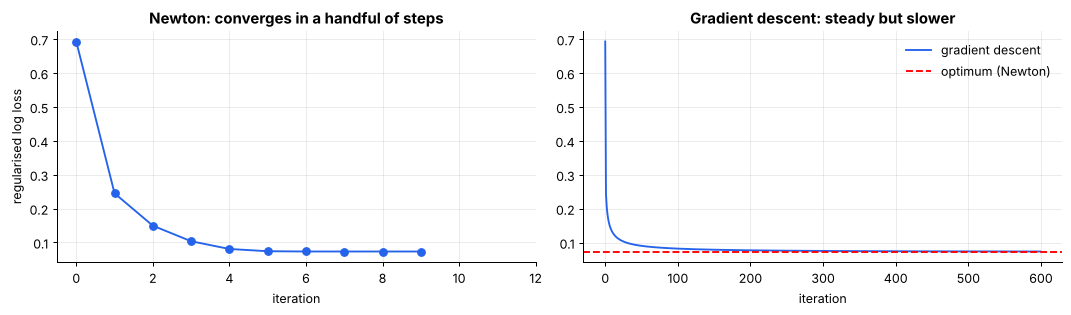

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
ax[0].plot(newton.loss_history_, "o-", label="Newton"); ax[0].set_title("Newton: converges in a handful of steps"); ax[0].set_xlabel("iteration"); ax[0].set_ylabel("regularised log loss"); ax[0].set_xlim(-0.5, 12)
ax[1].plot(gd.loss_history_[:600], label="gradient descent"); ax[1].axhline(newton.loss_history_[-1], color="r", ls="--", label="optimum (Newton)"); ax[1].set_title("Gradient descent: steady but slower"); ax[1].set_xlabel("iteration"); ax[1].legend()
plt.tight_layout(); plt.show()

> 🔑 **Key idea.**
>
> Our 35-line class reproduces scikit-learn's coefficients to ~10⁻⁶ (Newton) and the same accuracy. Newton needs only ~10 iterations because it exploits curvature; each iteration costs $O(np^2+p^3)$ though, so for huge *p* people use gradient-based solvers (`lbfgs`, `saga`), which is what scikit-learn does by default.

---
## 🏦 5. Loan approval end-to-end: and reading the coefficients

Now a realistic problem: **will a loan application be approved?** (3 000 synthetic applications, ~60 % approved.) We deliberately keep out two columns: `loan_id` (a meaningless identifier) and `interest_rate_offered`: *think about why a column like that might be dangerous*; Project 3 will reveal all.

In [8]:
loans = pd.read_csv(data_path("loan_approval.csv"))
loans["emi"] = loans["loan_amount_kes"] / loans["loan_term_months"] * 1.15                       # rough monthly instalment
loans["dti"] = (loans["monthly_debt_kes"] + loans["emi"]) / loans["monthly_income_kes"]          # debt-to-income ratio
loans["lti"] = loans["loan_amount_kes"] / (loans["monthly_income_kes"] * 12)                     # loan-to-annual-income
loans["log_income"] = np.log(loans["monthly_income_kes"]); loans["log_savings"] = np.log1p(loans["savings_balance_kes"])

num = ["credit_score", "credit_history_years", "dti", "lti", "log_income", "log_savings", "has_collateral", "age", "dependents", "existing_loans"]
cat = ["employment_type", "property_area", "education"]
X, y = loans[num + cat], loans["approved"]
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.25, stratify=y, random_state=RANDOM_STATE)
prep = ColumnTransformer([("num", make_pipeline(SimpleImputer(strategy="median"), StandardScaler()), num),
                          ("cat", OneHotEncoder(drop="first"), cat)])
model = make_pipeline(prep, LogisticRegression(max_iter=2000)).fit(Xtr, ytr)
proba = model.predict_proba(Xte)[:, 1]
print(f"accuracy = {accuracy_score(yte, proba >= .5):.3f}   ROC-AUC = {roc_auc_score(yte, proba):.3f}   baseline (always 'approve') = {yte.mean():.3f}")
display(pd.DataFrame(confusion_matrix(yte, proba >= .5), index=["actually rejected", "actually approved"], columns=["pred rejected", "pred approved"]))

accuracy = 0.864   ROC-AUC = 0.928   baseline (always 'approve') = 0.604


,pred rejected,pred approved
actually rejected,226,71
actually approved,31,422


**Feature engineering pays.** The raw columns (income, loan amount, term, debt) interact multiplicatively; a *linear* log-odds model can't build ratios by itself, but we can hand it the ratios. Compare:

In [9]:
raw_num = ["credit_score", "credit_history_years", "monthly_income_kes", "loan_amount_kes", "loan_term_months", "monthly_debt_kes", "has_collateral", "age", "dependents", "existing_loans", "savings_balance_kes"]
prep_raw = ColumnTransformer([("num", make_pipeline(SimpleImputer(strategy="median"), StandardScaler()), raw_num), ("cat", OneHotEncoder(drop="first"), cat)])
m_raw = make_pipeline(prep_raw, LogisticRegression(max_iter=2000)).fit(loans.loc[Xtr.index, raw_num + cat], ytr)
print(f"AUC with raw columns      : {roc_auc_score(yte, m_raw.predict_proba(loans.loc[Xte.index, raw_num + cat])[:, 1]):.3f}")
print(f"AUC with dti/lti features : {roc_auc_score(yte, proba):.3f}")

AUC with raw columns      : 0.876
AUC with dti/lti features : 0.928


Now interpret. Because numeric features were standardised, each coefficient is the change in log-odds per **one standard deviation** of that feature; $e^{w}$ is the odds multiplier.

,coef (log-odds),odds ratio e^coef
dti,-2.848,0.058
lti,-0.632,0.531
education_Not Graduate,-0.418,0.659
log_income,-0.054,0.947
existing_loans,0.026,1.026
age,0.052,1.053
employment_type_Self-Employed,0.073,1.076
dependents,0.095,1.099
property_area_Semi-urban,0.132,1.141
property_area_Urban,0.138,1.148


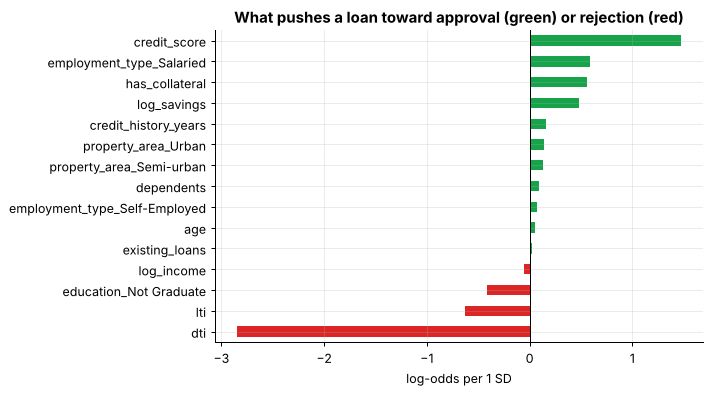

In [10]:
names = model[0].get_feature_names_out(); coefs = model[-1].coef_[0]
tbl = pd.DataFrame({"coef (log-odds)": coefs, "odds ratio e^coef": np.exp(coefs)}, index=[n.split("__")[1] for n in names]).sort_values("coef (log-odds)")
display(tbl.round(3))
tbl["coef (log-odds)"].plot.barh(color=["#dc2626" if c < 0 else "#16a34a" for c in tbl["coef (log-odds)"]], figsize=(7, 4.5)); plt.axvline(0, color="k", lw=0.8)
plt.title("What pushes a loan toward approval (green) or rejection (red)"); plt.xlabel("log-odds per 1 SD"); plt.show()

**Reading it:** a higher debt-to-income ratio is the strongest *negative* driver (odds fall by ~94 % per +1 SD, i.e. ×0.06); a higher credit score is the strongest *positive* one (odds ×4.3 per +1 SD); collateral and a salaried job help; very little else matters. A loan officer can *read* this, which is exactly why regulated industries (banking, insurance, healthcare) keep choosing logistic regression.

> ⚠️ **Watch out.**
>
> Coefficients are only comparable across features because we standardised. And, as ever, they describe **association in the data**, not causal effects. Also be careful with sensitive attributes (gender, marital status…): we left them out here on purpose; fairness is part of Project 3.

---
## 🧯 6. Regularisation and the problem with separable data

### 6a. When classes are perfectly separable, the unregularised model has no answer
If one line splits the classes perfectly, the likelihood keeps improving as the weights grow (a steeper sigmoid is *more* confident and *always* right), so the 'optimal' weights are **infinite**. Watch:

In [11]:
xs = np.array([[1.], [2.], [3.], [4.], [5.], [6.]]); ys = np.array([0, 0, 0, 1, 1, 1])
rows = []
for n_it in [10, 100, 1000, 10000]:
    m = LogisticRegressionScratch(C=np.inf, solver="gd", lr=0.5, n_iter=n_it, tol=0).fit(xs - 3.5, ys)
    rows.append({"GD iterations": n_it, "weight": m.coef_[0], "final loss": m.loss_history_[-1]})
display(pd.DataFrame(rows).round(4))
print("With an L2 penalty (C=1) the answer is finite:", LogisticRegressionScratch(C=1.0, solver="newton").fit(xs - 3.5, ys).coef_.round(3))

,GD iterations,weight,final loss
0,10,1.468,1.827e-01
1,100,3.599,5.290e-02
2,1000,7.482,7.800e-03
3,10000,12.056,8.000e-04


With an L2 penalty (C=1) the answer is finite: [1.121]


The weight keeps growing (slowly, logarithmically) while the loss creeps toward 0. This is why scikit-learn applies L2 regularisation **by default** (`C=1.0`): it's a safety net, not a luxury.

### 6b. The `C` dial: L2 vs L1
**Small C** → strong penalty → small weights, smoother/simpler model (high bias). **Large C** → weak penalty → flexible (high variance). **L2** shrinks all weights; **L1** drives many exactly to zero (feature selection).

,L2 train acc,L2 test acc,L2 ‖w‖,L1 non-zero weights,L1 test acc
C,,,,,
1.000e-04,0.641,0.632,0.049,0,0.626
3.162e-04,0.761,0.784,0.128,0,0.626
1.000e-03,0.889,0.889,0.273,0,0.626
3.162e-03,0.940,0.930,0.491,0,0.626
1.000e-02,0.952,0.947,0.791,2,0.825
3.162e-02,0.972,0.959,1.196,4,0.936
1.000e-01,0.982,0.982,1.744,7,0.971
3.162e-01,0.985,0.982,2.512,10,0.982
1.000e+00,0.987,0.971,3.654,15,0.977


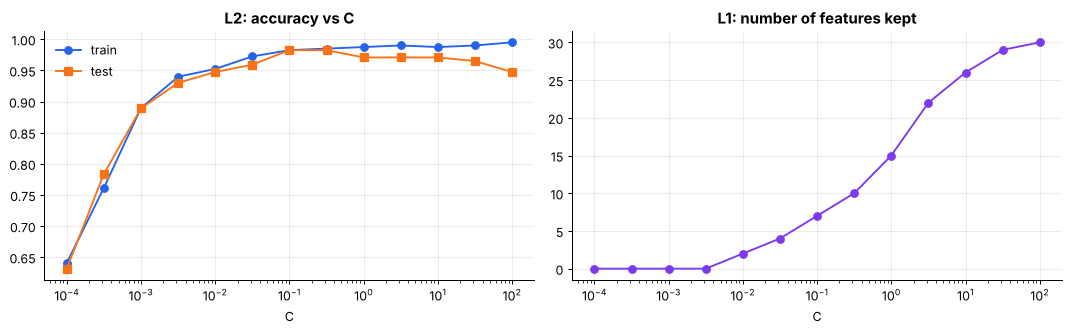

In [12]:
Cs = np.logspace(-4, 2, 13); rows = []
for C in Cs:
    l2 = LogisticRegression(C=C, max_iter=5000).fit(Ztr, yb_tr)
    l1 = LogisticRegression(l1_ratio=1, solver="saga", C=C, max_iter=20000).fit(Ztr, yb_tr)       # L1 penalty (scikit-learn >= 1.8)
    rows.append({"C": C, "L2 train acc": l2.score(Ztr, yb_tr), "L2 test acc": l2.score(Zte, yb_te), "L2 ‖w‖": np.linalg.norm(l2.coef_), "L1 non-zero weights": int((l1.coef_ != 0).sum()), "L1 test acc": l1.score(Zte, yb_te)})
res = pd.DataFrame(rows).set_index("C"); display(res.round(3))
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
ax[0].semilogx(res.index, res["L2 train acc"], "o-", label="train"); ax[0].semilogx(res.index, res["L2 test acc"], "s-", label="test"); ax[0].set_xlabel("C"); ax[0].set_title("L2: accuracy vs C"); ax[0].legend()
ax[1].semilogx(res.index, res["L1 non-zero weights"], "o-", color="#7c3aed"); ax[1].set_xlabel("C"); ax[1].set_title("L1: number of features kept"); plt.tight_layout(); plt.show()

---
## 🗺️ 7. Decision boundaries (and bending them)

With two features the boundary $w_1x_1+w_2x_2+b=0$ is a straight line. Perfect for blobs; hopeless for interleaved moons: *unless* we feed it polynomial features (just like Lesson 03).

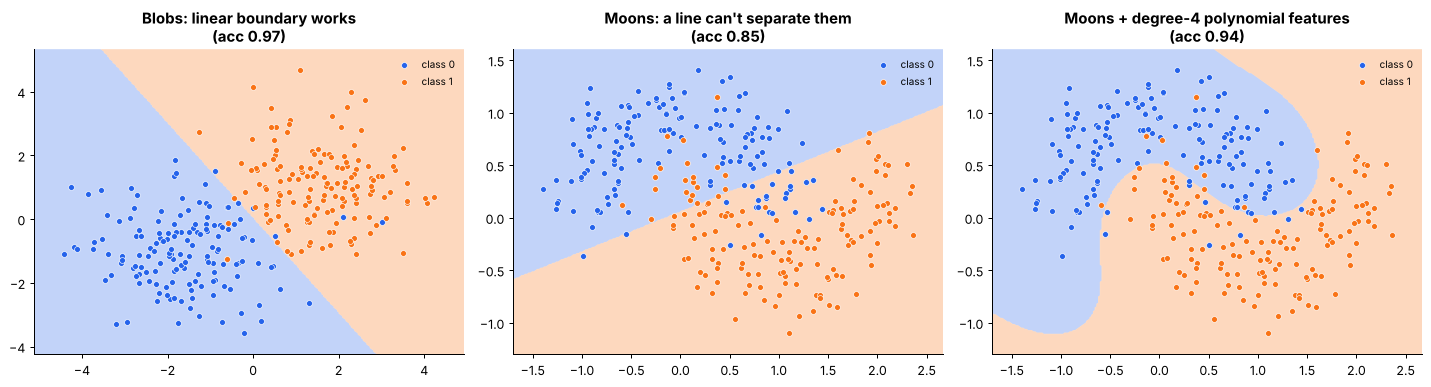

In [13]:
Xm, ym = make_moons(300, noise=0.25, random_state=1); Xs, ys_ = make_blobs(300, centers=[[-1.5, -1], [1.5, 1.2]], cluster_std=1.1, random_state=2)
fig, axes = plt.subplots(1, 3, figsize=(16, 4.4))
m1 = LogisticRegression().fit(Xs, ys_); plot_decision_boundary(m1, Xs, ys_, ax=axes[0], title=f"Blobs: linear boundary works\n(acc {m1.score(Xs, ys_):.2f})")
m2 = LogisticRegression().fit(Xm, ym); plot_decision_boundary(m2, Xm, ym, ax=axes[1], title=f"Moons: a line can't separate them\n(acc {m2.score(Xm, ym):.2f})")
m3 = make_pipeline(PolynomialFeatures(4), StandardScaler(), LogisticRegression(C=5, max_iter=5000)).fit(Xm, ym); plot_decision_boundary(m3, Xm, ym, ax=axes[2], title=f"Moons + degree-4 polynomial features\n(acc {m3.score(Xm, ym):.2f})")
plt.tight_layout(); plt.show()

The model is *still* logistic regression (linear in a richer feature space) which then looks curved in the original space. The same trick as polynomial regression, now for classification.

---
## 🌸 8. More than two classes: softmax vs one-vs-rest

Two strategies for $K$ classes:

- **One-vs-Rest (OvR):** train $K$ binary models ('class k vs everything else'), pick the class with the highest score.
- **Multinomial / softmax:** one model with a weight vector per class; probabilities are
$$P(y=k\mid\mathbf x)=\frac{e^{z_k}}{\sum_{j=1}^Ke^{z_j}},\qquad z_k=\mathbf w_k\cdot\mathbf x+b_k$$
(softmax generalises the sigmoid: for K = 2 it reduces to it.) scikit-learn uses softmax by default with `lbfgs`.

In [14]:
iris = load_iris(); Xi_tr, Xi_te, yi_tr, yi_te = train_test_split(iris.data, iris.target, test_size=0.3, stratify=iris.target, random_state=RANDOM_STATE)
soft = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)).fit(Xi_tr, yi_tr)
ovr = make_pipeline(StandardScaler(), OneVsRestClassifier(LogisticRegression(max_iter=1000))).fit(Xi_tr, yi_tr)
print(f"softmax test acc = {soft.score(Xi_te, yi_te):.3f}   |   one-vs-rest test acc = {ovr.score(Xi_te, yi_te):.3f}")

# softmax by hand, from the fitted weights
lr_ = soft[-1]; z = lr_.intercept_ + soft[0].transform(Xi_te[:1]) @ lr_.coef_.T
manual = np.exp(z) / np.exp(z).sum()
print("manual softmax probabilities:", manual.round(4)[0], "\nsklearn predict_proba       :", soft.predict_proba(Xi_te[:1]).round(4)[0], "->", iris.target_names[soft.predict(Xi_te[:1])[0]])

softmax test acc = 0.911   |   one-vs-rest test acc = 0.844
manual softmax probabilities: [0.     0.1014 0.8985] 
sklearn predict_proba       : [0.     0.1014 0.8985] -> virginica


---
## 📋 9. Cheat-sheet: the full profile of Logistic Regression

| Question | Answer |
|---|---|
| **Underlying concept** | A linear score squashed by the sigmoid into a probability; log-odds are linear in the features. |
| **How it works** | Fit weights by minimising the (regularised) log loss with Newton/IRLS or gradient-based solvers; predict P(y=1), compare with a threshold. |
| **Mathematical foundation** | Maximum likelihood; sigmoid/logit; convex log-loss; gradient Xᵀ(p−y)/n; Hessian XᵀWX; L1/L2 priors; softmax for K classes. |
| **Important parameters** | `C` (inverse regularisation), L1/L2 via `l1_ratio`/penalty, `solver` (lbfgs/liblinear/saga/newton-cg), `class_weight`, `max_iter`, the decision threshold (not a model parameter!). Scale features. |
| **Advantages** | Fast, stable, convex; probabilistic outputs; interpretable (odds ratios); works well with limited data; regularisation built in; easy to deploy and monitor. |
| **Disadvantages** | Linear decision boundary; needs feature engineering for interactions/non-linearity; sensitive to outliers & multicollinearity; probabilities can be off with severe imbalance. |
| **Complexity** | Training ≈ O(n·p) per gradient step (×iterations) or O(n·p² + p³) per Newton step; prediction O(p); memory O(p). |
| **Use cases** | Credit scoring, medical risk, churn, click/conversion prediction, spam baselines, any task where you must explain *why* and need calibrated probabilities. |
| **Limitations** | Cannot model XOR-like or curved boundaries on raw features; perfect separation → needs regularisation; assumes additive effects on the log-odds scale. |

---
## 🧪 10. More worked examples

### Worked Example 1: From log-odds to probability

A spam model has intercept $-3$, and weights $+1.2$ for 'contains the word FREE' and $+0.8$ for 'has ≥ 3 exclamation marks'. An email has both.

$z=-3+1.2+0.8=-1.0$ → $p=\sigma(-1)=\dfrac{1}{1+e^{1}}=0.269$. Odds $=0.269/0.731=0.368=e^{-1}$. Not yet spam at threshold 0.5. If we also add a 'sender unknown' feature (+1.5), $z=0.5$ and $p=0.622$.

In [15]:
for z_ in [-1.0, 0.5]: print(f"z={z_:>4} -> p = {1 / (1 + np.exp(-z_)):.3f}, odds = {np.exp(z_):.3f}")

z=-1.0 -> p = 0.269, odds = 0.368
z= 0.5 -> p = 0.622, odds = 1.649


### Worked Example 2: One gradient step by hand

One example $x=2$, $y=1$; start with $w=0,\ b=0$; learning rate 0.5. $p=\sigma(0)=0.5$; error $p-y=-0.5$. Gradients: $\partial J/\partial w=x(p-y)=2\times(-0.5)=-1$, $\partial J/\partial b=-0.5$. Update: $w=0-0.5(-1)=0.5$, $b=0-0.5(-0.5)=0.25$. New score at $x=2$: $z=0.5\cdot2+0.25=1.25$, $p=\sigma(1.25)=0.777$: the model became more confident in the right answer.

In [16]:
w_, b_ = 0.0, 0.0; x_, y_ = 2.0, 1.0; p_ = 1 / (1 + np.exp(0))
gw, gb = x_ * (p_ - y_), (p_ - y_); w_, b_ = w_ - 0.5 * gw, b_ - 0.5 * gb
print("w, b =", w_, b_, "| new p =", round(1 / (1 + np.exp(-(w_ * x_ + b_))), 3))

w, b = 0.5 0.25 | new p = 0.777


---
### 🧩 Problem 1: Sigmoid, odds and log-odds  ⭐

Write `sigmoid(z)`, `odds(p)` and `logit(p)` (the inverse of the sigmoid). Compute: `p1 = sigmoid(1.386)` (≈ 0.8), `o1 = odds(0.8)`, `l1 = logit(0.8)`, and verify the round trip with `roundtrip = sigmoid(logit(0.3))` (should return 0.3).

In [17]:
# ✅ SOLUTION
def sigmoid(z):
    return 1 / (1 + np.exp(-z))

def odds(p):
    return p / (1 - p)

def logit(p):
    return np.log(odds(p))

p1 = sigmoid(1.386); o1 = odds(0.8); l1 = logit(0.8); roundtrip = sigmoid(logit(0.3))
print(p1, o1, l1, roundtrip)

0.7999528980616638 4.000000000000001 1.3862943611198908 0.30000000000000004


**Why this works.** A probability of 0.8 means odds of 4:1 and log-odds of ln 4 ≈ 1.386. The sigmoid and logit are inverse functions, translating between the unbounded linear world and the bounded probability world.

In [18]:
check("sigmoid(1.386) ≈ 0.8", lambda: abs(p1 - 0.8) < 1e-3)
check("odds(0.8) = 4", lambda: abs(o1 - 4) < 1e-9)
check("logit(0.8) ≈ 1.386", lambda: abs(l1 - 1.3863) < 1e-3)
check("round trip returns 0.3", lambda: abs(roundtrip - 0.3) < 1e-9)

✅  sigmoid(1.386) ≈ 0.8
✅  odds(0.8) = 4
✅  logit(0.8) ≈ 1.386
✅  round trip returns 0.3


---
### 🧩 Problem 2: Log loss and its gradient, by hand  ⭐⭐

Data: `X = [[1.0], [2.0], [3.0]]`, `y = [0, 0, 1]`, current parameters `w = 0.5`, `b = -1.0`.

Compute `p` (the three predicted probabilities), `loss` (mean log loss), and the gradients `grad_w`, `grad_b` using the formulas $\frac1n X^\top(p-y)$ and $\frac1n\sum(p-y)$. Then verify `grad_w` numerically with a finite difference `(loss(w+h) − loss(w−h)) / 2h` for `h = 1e-6` and store it in `grad_w_numeric`.

In [19]:
# ✅ SOLUTION
X = np.array([[1.0], [2.0], [3.0]]); y = np.array([0, 0, 1]); w, b = 0.5, -1.0
def L(w_, b_):
    p_ = 1 / (1 + np.exp(-(w_ * X[:, 0] + b_)))
    return -np.mean(y * np.log(p_) + (1 - y) * np.log(1 - p_))

p = 1 / (1 + np.exp(-(w * X[:, 0] + b))); loss = L(w, b)
grad_w = np.mean(X[:, 0] * (p - y)); grad_b = np.mean(p - y)
h = 1e-6; grad_w_numeric = (L(w + h, b) - L(w - h, b)) / (2 * h)
print(p.round(4), round(loss, 4), round(grad_w, 4), round(grad_b, 4), round(grad_w_numeric, 4))

[0.3775 0.5    0.6225] 0.5471 0.0816 0.1667 0.0816


**Why this works.** The finite-difference check is the standard way to verify any gradient you derive by hand: the formula Xᵀ(p−y)/n really is the slope of the log loss.

In [20]:
check("probabilities ≈ [0.378, 0.5, 0.622]", lambda: np.allclose(p, [0.3775, 0.5, 0.6225], atol=1e-3))
check("loss ≈ 0.5471", lambda: abs(loss - 0.5471) < 1e-3)
check("analytic gradient matches the numeric one", lambda: abs(grad_w - grad_w_numeric) < 1e-6)
check("grad_b ≈ 0.1667", lambda: abs(grad_b - 0.16667) < 1e-3)

✅  probabilities ≈ [0.378, 0.5, 0.622]
✅  loss ≈ 0.5471
✅  analytic gradient matches the numeric one
✅  grad_b ≈ 0.1667


---
### 🧩 Problem 3: Implement predict_proba from a fitted model  ⭐

Fit `lr_cancer = LogisticRegression(C=1.0, max_iter=10000).fit(Ztr, yb_tr)`. Using **only** `lr_cancer.coef_` and `lr_cancer.intercept_` (no `predict_proba`), compute `my_proba` for the standardised test set `Zte`, and store `max_gap` = max absolute difference vs `lr_cancer.predict_proba(Zte)[:, 1]`. Then find `boundary_dist` for the first test sample: its signed distance from the decision boundary, `z / ‖w‖`.

In [21]:
# ✅ SOLUTION
lr_cancer = LogisticRegression(C=1.0, max_iter=10000).fit(Ztr, yb_tr)
z_ = Zte @ lr_cancer.coef_[0] + lr_cancer.intercept_[0]
my_proba = 1 / (1 + np.exp(-z_))
max_gap = np.abs(my_proba - lr_cancer.predict_proba(Zte)[:, 1]).max()
boundary_dist = z_[0] / np.linalg.norm(lr_cancer.coef_[0])
print(max_gap, boundary_dist)

4.336808689942018e-19 -0.5628188926776914


**Why this works.** A trained logistic regression is just a weight vector and an intercept: ŷ = σ(w·x + b). Deployment can be a one-line formula in any language.

In [22]:
check("manual probabilities equal predict_proba", lambda: max_gap < 1e-10)
check("distance has the same sign as the decision", lambda: np.sign(boundary_dist) == (1 if lr_cancer.predict(Zte[:1])[0] == 1 else -1))

✅  manual probabilities equal predict_proba
✅  distance has the same sign as the decision


---
### 🧩 Problem 4: Read the loan model  ⭐⭐

Using `tbl` (coefficients and odds ratios of the loan model): set `strongest_positive` and `strongest_negative` to the *names* of the features with the largest and smallest coefficients, `or_credit` = the odds ratio of `credit_score`, and `pct_change_dti` = the percentage change in the odds of approval for +1 SD in `dti` (negative number). Finally `prob_after` = the probability after a customer whose current approval probability is 0.50 improves their credit score by +1 SD (odds multiply by `or_credit`).

In [23]:
# ✅ SOLUTION
strongest_positive = tbl["coef (log-odds)"].idxmax(); strongest_negative = tbl["coef (log-odds)"].idxmin()
or_credit = tbl.loc["credit_score", "odds ratio e^coef"]
pct_change_dti = (tbl.loc["dti", "odds ratio e^coef"] - 1) * 100
new_odds = 1.0 * or_credit; prob_after = new_odds / (1 + new_odds)
print(strongest_positive, strongest_negative, round(or_credit, 2), round(pct_change_dti, 1), round(prob_after, 3))

credit_score dti 4.36 -94.2 0.813


**Why this works.** Odds ×4.3 sounds dramatic, but remember probabilities are bounded: a customer at 50 % moves to about 81 %, not 215 %. Converting back to probabilities is how you communicate results to non-statisticians.

In [24]:
check("credit_score is the strongest positive driver", lambda: strongest_positive == "credit_score")
check("dti is the strongest negative driver", lambda: strongest_negative == "dti")
check("odds ratio of credit score > 3", lambda: or_credit > 3)
check("higher dti cuts the odds by more than 90%", lambda: pct_change_dti < -90)
check("0.5 -> about 0.8 after a +1 SD credit score", lambda: 0.75 < prob_after < 0.9)

✅  credit_score is the strongest positive driver
✅  dti is the strongest negative driver
✅  odds ratio of credit score > 3
✅  higher dti cuts the odds by more than 90%
✅  0.5 -> about 0.8 after a +1 SD credit score


---
### 🧩 Problem 5: Pick C by cross-validation  ⭐⭐

Using `Ztr, yb_tr` (standardised cancer training data), evaluate `LogisticRegression(C=C, max_iter=5000)` for `C ∈ np.logspace(-3, 2, 11)` with **stratified 5-fold CV** (`StratifiedKFold(5, shuffle=True, random_state=0)`, scoring `'roc_auc'`) → dict `cv_auc` (C → mean AUC). Store `best_C` (the C with the highest AUC; take the **smallest** C in case of ties within 0.0005; prefer more regularisation) and the test AUC `test_auc` of that model.

In [25]:
# ✅ SOLUTION
skf = StratifiedKFold(5, shuffle=True, random_state=0)
cv_auc = {C: cross_val_score(LogisticRegression(C=C, max_iter=5000), Ztr, yb_tr, cv=skf, scoring="roc_auc").mean() for C in np.logspace(-3, 2, 11)}
top = max(cv_auc.values()); best_C = min(c for c, v in cv_auc.items() if v >= top - 0.0005)
test_auc = roc_auc_score(yb_te, LogisticRegression(C=best_C, max_iter=5000).fit(Ztr, yb_tr).predict_proba(Zte)[:, 1])
print(round(best_C, 4), round(top, 4), round(test_auc, 4))

0.1 0.9929 0.9988


**Why this works.** On this easy dataset moderate regularisation is best: C too small underfits, C too large starts to chase noise. The 'smallest C within tolerance' rule is a mini one-standard-error rule: prefer the simpler model when scores tie.

In [26]:
check("11 values of C evaluated", lambda: len(cv_auc) == 11)
check("very strong regularisation (C=0.001) is worse than the best", lambda: cv_auc[min(cv_auc)] < max(cv_auc.values()))
check("test AUC > 0.98", lambda: test_auc > 0.98)

✅  11 values of C evaluated
✅  very strong regularisation (C=0.001) is worse than the best
✅  test AUC > 0.98


---
### 🧩 Problem 6: Make a line bend  ⭐⭐

On the moons data `Xm, ym`, compare the test accuracy of plain `LogisticRegression()` and `make_pipeline(PolynomialFeatures(d), StandardScaler(), LogisticRegression(C=5, max_iter=5000))` for `d = 1…6`. Use `train_test_split(Xm, ym, test_size=0.3, random_state=0)`. Store accuracies in `acc_by_degree` (dict d → test acc) and `best_d`.

In [27]:
# ✅ SOLUTION
Xm_tr, Xm_te, ym_tr, ym_te = train_test_split(Xm, ym, test_size=0.3, random_state=0)
acc_by_degree = {d: make_pipeline(PolynomialFeatures(d), StandardScaler(), LogisticRegression(C=5, max_iter=5000)).fit(Xm_tr, ym_tr).score(Xm_te, ym_te) for d in range(1, 7)}
best_d = max(acc_by_degree, key=acc_by_degree.get); print({k: round(v, 3) for k, v in acc_by_degree.items()}, best_d)

{1: 0.867, 2: 0.833, 3: 0.944, 4: 0.922, 5: 0.889, 6: 0.878} 3


**Why this works.** Feeding squares, cubes and cross-products lets the *linear* log-odds model carve a curved boundary: the same feature-expansion idea as polynomial regression, and the doorway to kernel SVMs.

In [28]:
check("six degrees evaluated", lambda: len(acc_by_degree) == 6)
check("a curved boundary beats the straight line", lambda: acc_by_degree[best_d] > acc_by_degree[1] + 0.02)
check("best degree is above 1", lambda: best_d > 1)

✅  six degrees evaluated
✅  a curved boundary beats the straight line
✅  best degree is above 1


---
## 🧠 Check Your Understanding
Answer each question in your head (or on paper) *before* opening the answer.

**Q1.** A logistic regression coefficient is 0.693. What is the odds ratio and what does it mean?

<details><summary>👀 Show answer</summary>

e^0.693 = 2. Each +1 unit of that feature **doubles** the odds of the positive class (holding others constant).

</details>

**Q2.** Why can't we minimise squared error for logistic regression with the same closed-form trick as linear regression?

<details><summary>👀 Show answer</summary>

The model is non-linear in the weights (through the sigmoid), so the normal equations have no closed-form solution; we optimise the convex log loss iteratively.

</details>

**Q3.** Your classes are perfectly separable and you set `C=np.inf`. What happens to the weights?

<details><summary>👀 Show answer</summary>

They grow without bound: a steeper sigmoid always fits better. Regularisation (finite C) keeps the solution finite.

</details>

**Q4.** Is the decision boundary of logistic regression linear? Can it be made non-linear?

<details><summary>👀 Show answer</summary>

It is linear in the features given (w·x + b = 0). Add polynomial/interaction features (or use a kernel method) to get curved boundaries in the original space.

</details>

**Q5.** Why must we standardise features before comparing coefficients, and before using L1/L2 penalties?

<details><summary>👀 Show answer</summary>

Penalties and coefficient magnitudes depend on feature scale: a feature measured in large units gets a tiny coefficient and is barely penalised, so scales must be comparable.

</details>

---
## 🔁 Recap

- Logistic regression: log-odds are linear in the features; the sigmoid turns them into probabilities.
- Trained by maximum likelihood = minimising the convex log loss; gradient = Xᵀ(p−y)/n; Newton/IRLS converges in a few steps.
- exp(coefficient) is an odds ratio: the key to interpretation (standardise to compare features).
- L2/L1 regularisation (C) is essential, especially for separable data; polynomial features bend the boundary.
- Softmax extends it to many classes; the threshold, not the model, encodes your business costs.

### ➡️ Up next: **Decision Tree Classification**
Open `11_Decision_Tree_Classification.ipynb` when you're ready.

*You did the hard part: you thought about it, not just ran it. See you in the next one!* 🚀